In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import roc_auc_score, brier_score_loss, accuracy_score
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.base import clone

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BIOMARKERS = ['hsa-miR-337-3p', 'hsa-miR-200a-3p', 'hsa-miR-1307-5p']
LABEL_COL  = 'type'              # 0 = control, 1 = case (positive class)

TRAIN_FILE = 'GSE211692_Raw_Full_Probe.csv'
TEST_FILE  = 'GSE113486_Raw_Full_Probe.csv'
print('Biomarkers:', BIOMARKERS)

Biomarkers: ['hsa-miR-337-3p', 'hsa-miR-200a-3p', 'hsa-miR-1307-5p']


1. Load data and extract the 2-miRNA panel

In [2]:
def load_panel(path):
    """Read a raw probe file and return (X[2 miRNAs], y[type])."""
    df = pd.read_csv(path, index_col=0)
    missing = [m for m in BIOMARKERS if m not in df.columns]
    if missing:
        raise KeyError(f'{path}: missing biomarkers {missing}')
    X = df[BIOMARKERS].astype(float).copy()
    y = df[LABEL_COL].astype(int).copy()
    return X, y

X_train, y_train = load_panel(TRAIN_FILE)
X_test,  y_test  = load_panel(TEST_FILE)

scaler = StandardScaler()

X_train_scaled_array = scaler.fit_transform(X_train)

X_test_scaled_array = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=X_test.columns, index=X_test.index)

X_train = X_train_scaled
X_test = X_test_scaled

print("\n--- After Z-Score Normalization ---")
display(X_train_scaled.head())

print('TRAIN', TRAIN_FILE)
print('  X:', X_train.shape, '| class balance:', y_train.value_counts().to_dict())
print('TEST ', TEST_FILE)
print('  X:', X_test.shape,  '| class balance:', y_test.value_counts().to_dict())
display(X_train.head())


--- After Z-Score Normalization ---


,hsa-miR-337-3p,hsa-miR-200a-3p,hsa-miR-1307-5p
GSM6483171,-1.116345,-0.468549,-1.469937
GSM6483172,-1.280283,-0.595841,-1.650342
GSM6483173,-1.178385,-0.516720,-1.538208
GSM6483174,-1.548154,-0.803833,-1.945121
GSM6483175,-1.506247,-0.771295,-1.899005


TRAIN GSE211692_Raw_Full_Probe.csv
  X: (1563, 3) | class balance: {0: 857, 1: 706}
TEST  GSE113486_Raw_Full_Probe.csv
  X: (140, 3) | class balance: {0: 100, 1: 40}


,hsa-miR-337-3p,hsa-miR-200a-3p,hsa-miR-1307-5p
GSM6483171,-1.116345,-0.468549,-1.469937
GSM6483172,-1.280283,-0.595841,-1.650342
GSM6483173,-1.178385,-0.516720,-1.538208
GSM6483174,-1.548154,-0.803833,-1.945121
GSM6483175,-1.506247,-0.771295,-1.899005


2. Model panel and hyperparameters grids

In [3]:
MODELS = {
    'Logistic Ridge': (
        LogisticRegression(penalty='l2', solver='lbfgs', max_iter=5000,
                           random_state=RANDOM_STATE),
        {'clf__C': [0.01, 0.1, 1, 10]},
    ),
    'ElasticNet': (
        LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000,
                           random_state=RANDOM_STATE),
        {'clf__C': [0.1, 1, 10], 'clf__l1_ratio': [0.2, 0.5, 0.8]},
    ),
    'SVM': (
        SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
        {'clf__C': [1, 10], 'clf__gamma': ['scale']},
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {'clf__n_estimators': [200, 400], 'clf__max_depth': [None, 4, 8]},
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.05, 0.1],
         'clf__max_depth': [2, 3]},
    ),
    'XGBoost': (
        XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='logloss',
                      verbosity=0, tree_method='hist'),
        {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.05, 0.1],
         'clf__max_depth': [2, 3]},
    ),
    'KNN': (
        KNeighborsClassifier(),
        {'clf__n_neighbors': [5, 11, 21], 'clf__weights': ['uniform', 'distance']},
    ),
    'Naive Bayes': (
        GaussianNB(),
        {'clf__var_smoothing': [1e-9, 1e-8, 1e-7]},
    ),
    'LDA': (
        LinearDiscriminantAnalysis(),
        [{'clf__solver': ['svd']},
         {'clf__solver': ['lsqr', 'eigen'], 'clf__shrinkage': [None, 'auto']}],
    ),
}

def make_pipe(estimator, scale):
    """Wrap an estimator with StandardScaler (scale=True) or passthrough."""
    scaler = StandardScaler() if scale else 'passthrough'
    return Pipeline([('scaler', scaler), ('clf', estimator)])

print(f'{len(MODELS)} models x 2 scaling variants = {len(MODELS)*2} configurations')

9 models x 2 scaling variants = 18 configurations


3. Nested cross-validation on the training set

In [4]:
OUTER_K, INNER_K = 10, 5

def evaluate_fold(estimator, grid, X_tr, y_tr, X_te, y_te, scale):
    inner = StratifiedKFold(n_splits=INNER_K, shuffle=True, random_state=RANDOM_STATE)
    gs = GridSearchCV(make_pipe(estimator, scale), grid,
                      scoring='roc_auc', cv=inner, n_jobs=-1, refit=True)
    gs.fit(X_tr, y_tr)
    best = gs.best_estimator_
    proba = best.predict_proba(X_te)[:, 1]
    pred  = best.predict(X_te)
    return {
        'ROC-AUC':  roc_auc_score(y_te, proba),
        'Brier':    brier_score_loss(y_te, proba),
        'Accuracy': accuracy_score(y_te, pred),
        'best_params': gs.best_params_,
    }

def nested_cv(name, estimator, grid, X, y, scale):
    outer = StratifiedKFold(n_splits=OUTER_K, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    Xv, yv = X.values, y.values
    for fold, (tr, te) in enumerate(outer.split(Xv, yv), 1):
        r = evaluate_fold(estimator, grid,
                          Xv[tr], yv[tr], Xv[te], yv[te], scale)
        rows.append(r)
    return pd.DataFrame(rows)

In [5]:
# Run nested CV for every (model, scaling) pair. (A few minutes on 16 cores.)
import time

cv_records = []
for name, (estimator, grid) in MODELS.items():
    for scale in (True, False):
        t0 = time.time()
        folds = nested_cv(name, estimator, grid, X_train, y_train, scale)
        for m in ('ROC-AUC', 'Brier', 'Accuracy'):
            cv_records.append({
                'Model': name,
                'Scaling': 'scaled' if scale else 'unscaled',
                'Metric': m,
                'Mean': folds[m].mean(),
                'Std':  folds[m].std(),
            })
        print(f'{name:<18} {"scaled" if scale else "unscaled":<9} '
              f'AUC={folds["ROC-AUC"].mean():.3f}  '
              f'Brier={folds["Brier"].mean():.3f}  '
              f'Acc={folds["Accuracy"].mean():.3f}  '
              f'({time.time()-t0:.1f}s)')

cv_df = pd.DataFrame(cv_records)

Logistic Ridge     scaled    AUC=0.766  Brier=0.196  Acc=0.653  (6.2s)
Logistic Ridge     unscaled  AUC=0.766  Brier=0.196  Acc=0.653  (1.5s)
ElasticNet         scaled    AUC=0.766  Brier=0.196  Acc=0.654  (3.7s)
ElasticNet         unscaled  AUC=0.766  Brier=0.196  Acc=0.654  (3.1s)
SVM                scaled    AUC=0.934  Brier=0.097  Acc=0.872  (18.7s)
SVM                unscaled  AUC=0.934  Brier=0.097  Acc=0.872  (17.9s)
Random Forest      scaled    AUC=0.933  Brier=0.096  Acc=0.875  (236.8s)
Random Forest      unscaled  AUC=0.933  Brier=0.096  Acc=0.875  (250.7s)
Gradient Boosting  scaled    AUC=0.927  Brier=0.101  Acc=0.863  (152.7s)
Gradient Boosting  unscaled  AUC=0.927  Brier=0.101  Acc=0.863  (161.5s)
XGBoost            scaled    AUC=0.931  Brier=0.098  Acc=0.871  (19.0s)
XGBoost            unscaled  AUC=0.931  Brier=0.098  Acc=0.871  (18.5s)
KNN                scaled    AUC=0.928  Brier=0.101  Acc=0.865  (4.0s)
KNN                unscaled  AUC=0.928  Brier=0.101  Acc=0.864  (

3.1 Nested-CV results (mean ± std across the 10 outer folds)

In [6]:
def pivot_metric(metric):
    sub = cv_df[cv_df['Metric'] == metric].copy()
    sub['value'] = sub.apply(lambda r: f"{r['Mean']:.3f} ± {r['Std']:.3f}", axis=1)
    return sub.pivot(index='Model', columns='Scaling', values='value')

for metric in ('ROC-AUC', 'Brier', 'Accuracy'):
    print(f'\n===== {metric} (nested 10-fold CV on TRAIN) =====')
    display(pivot_metric(metric).loc[list(MODELS.keys())])


===== ROC-AUC (nested 10-fold CV on TRAIN) =====


Scaling,scaled,unscaled
Model,,
Logistic Ridge,0.766 ± 0.027,0.766 ± 0.027
ElasticNet,0.766 ± 0.027,0.766 ± 0.027
SVM,0.934 ± 0.023,0.934 ± 0.023
Random Forest,0.933 ± 0.026,0.933 ± 0.026
Gradient Boosting,0.927 ± 0.024,0.927 ± 0.024
XGBoost,0.931 ± 0.023,0.931 ± 0.023
KNN,0.928 ± 0.023,0.928 ± 0.022
Naive Bayes,0.777 ± 0.023,0.777 ± 0.023
LDA,0.765 ± 0.027,0.765 ± 0.027



===== Brier (nested 10-fold CV on TRAIN) =====


Scaling,scaled,unscaled
Model,,
Logistic Ridge,0.196 ± 0.011,0.196 ± 0.011
ElasticNet,0.196 ± 0.011,0.196 ± 0.011
SVM,0.097 ± 0.015,0.097 ± 0.015
Random Forest,0.096 ± 0.016,0.096 ± 0.016
Gradient Boosting,0.101 ± 0.017,0.101 ± 0.017
XGBoost,0.098 ± 0.016,0.098 ± 0.016
KNN,0.101 ± 0.014,0.101 ± 0.014
Naive Bayes,0.189 ± 0.009,0.189 ± 0.009
LDA,0.196 ± 0.011,0.196 ± 0.011



===== Accuracy (nested 10-fold CV on TRAIN) =====


Scaling,scaled,unscaled
Model,,
Logistic Ridge,0.653 ± 0.025,0.653 ± 0.025
ElasticNet,0.654 ± 0.025,0.654 ± 0.025
SVM,0.872 ± 0.025,0.872 ± 0.025
Random Forest,0.875 ± 0.029,0.875 ± 0.029
Gradient Boosting,0.863 ± 0.030,0.863 ± 0.030
XGBoost,0.871 ± 0.023,0.871 ± 0.023
KNN,0.865 ± 0.025,0.864 ± 0.024
Naive Bayes,0.649 ± 0.020,0.649 ± 0.020
LDA,0.647 ± 0.024,0.647 ± 0.024


In [7]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Pool the 10 outer-fold held-out probabilities into one OOF vector per (model, scaling).
def nested_cv_oof(estimator, grid, X, y, scale):
    outer = StratifiedKFold(n_splits=OUTER_K, shuffle=True, random_state=RANDOM_STATE)
    Xv, yv = X.values, y.values
    oof = np.full(len(yv), np.nan)
    for tr, te in outer.split(Xv, yv):
        inner = StratifiedKFold(n_splits=INNER_K, shuffle=True, random_state=RANDOM_STATE)
        gs = GridSearchCV(make_pipe(estimator, scale), grid,
                          scoring='roc_auc', cv=inner, n_jobs=-1, refit=True)
        gs.fit(Xv[tr], yv[tr])
        oof[te] = gs.best_estimator_.predict_proba(Xv[te])[:, 1]
    return oof

oof_proba, oof_rows = {}, []
for name, (estimator, grid) in MODELS.items():
    for scale in (True, False):
        variant = 'scaled' if scale else 'unscaled'
        oof = nested_cv_oof(estimator, grid, X_train, y_train, scale)
        oof_proba[(name, variant)] = oof
        oof_rows.append({'Model': name, 'Scaling': variant,
                         'ROC-AUC': roc_auc_score(y_train, oof),
                         'AP':      average_precision_score(y_train, oof),
                         'Brier':   brier_score_loss(y_train, oof)})
oof_df = pd.DataFrame(oof_rows).set_index(['Model', 'Scaling'])
print('Pooled out-of-fold metrics (nested CV, TRAIN GSE211692):')
display(oof_df.round(3))

Pooled out-of-fold metrics (nested CV, TRAIN GSE211692):


ROC-AUC     AP  Brier
Model             Scaling                        
Logistic Ridge    scaled      0.764  0.692  0.196
                  unscaled    0.765  0.691  0.196
ElasticNet        scaled      0.765  0.691  0.196
                  unscaled    0.765  0.691  0.196
SVM               scaled      0.933  0.891  0.097
                  unscaled    0.933  0.891  0.097
Random Forest     scaled      0.932  0.868  0.096
                  unscaled    0.932  0.868  0.096
Gradient Boosting scaled      0.928  0.876  0.101
                  unscaled    0.928  0.876  0.101
XGBoost           scaled      0.930  0.871  0.098
                  unscaled    0.930  0.871  0.098
KNN               scaled      0.927  0.874  0.101
                  unscaled    0.927  0.874  0.101
Naive Bayes       scaled      0.778  0.687  0.189
                  unscaled    0.778  0.687  0.189
LDA               scaled      0.764  0.691  0.196
                  unscaled    0.764  0.691  0.196

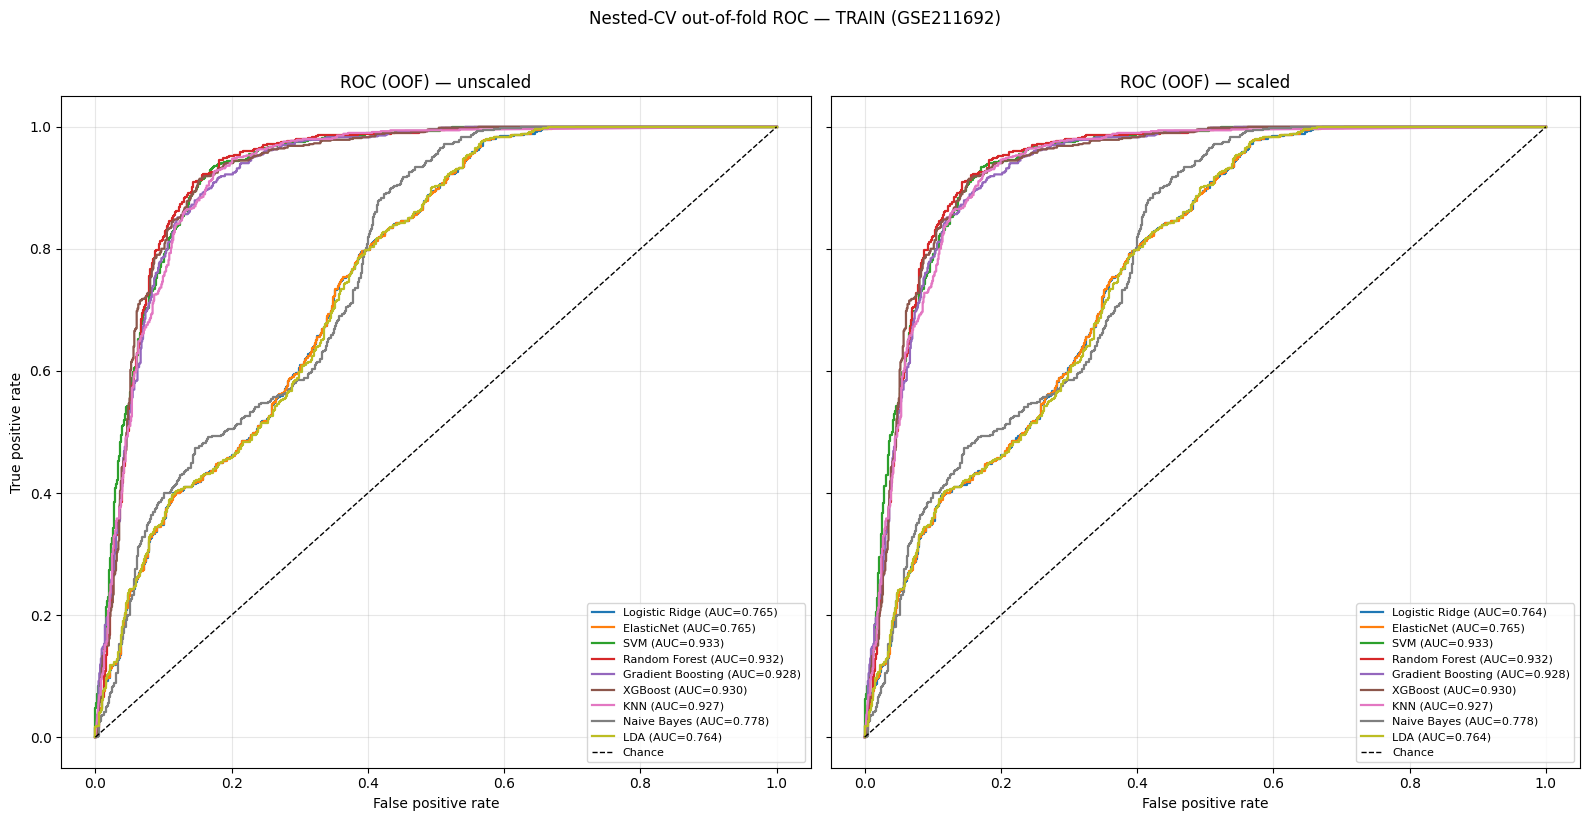

In [8]:
# OOF ROC curves for both scaling variants (nested CV on TRAIN).
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    for name in MODELS:
        fpr, tpr, _ = roc_curve(y_train, oof_proba[(name, variant)])
        ax.plot(fpr, tpr, lw=1.6,
                label=f"{name} (AUC={oof_df.loc[(name, variant), 'ROC-AUC']:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
    ax.set_xlabel('False positive rate'); ax.set_title(f'ROC (OOF) — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('True positive rate')
plt.suptitle('Nested-CV out-of-fold ROC — TRAIN (GSE211692)', y=1.02)
plt.tight_layout(); plt.show()

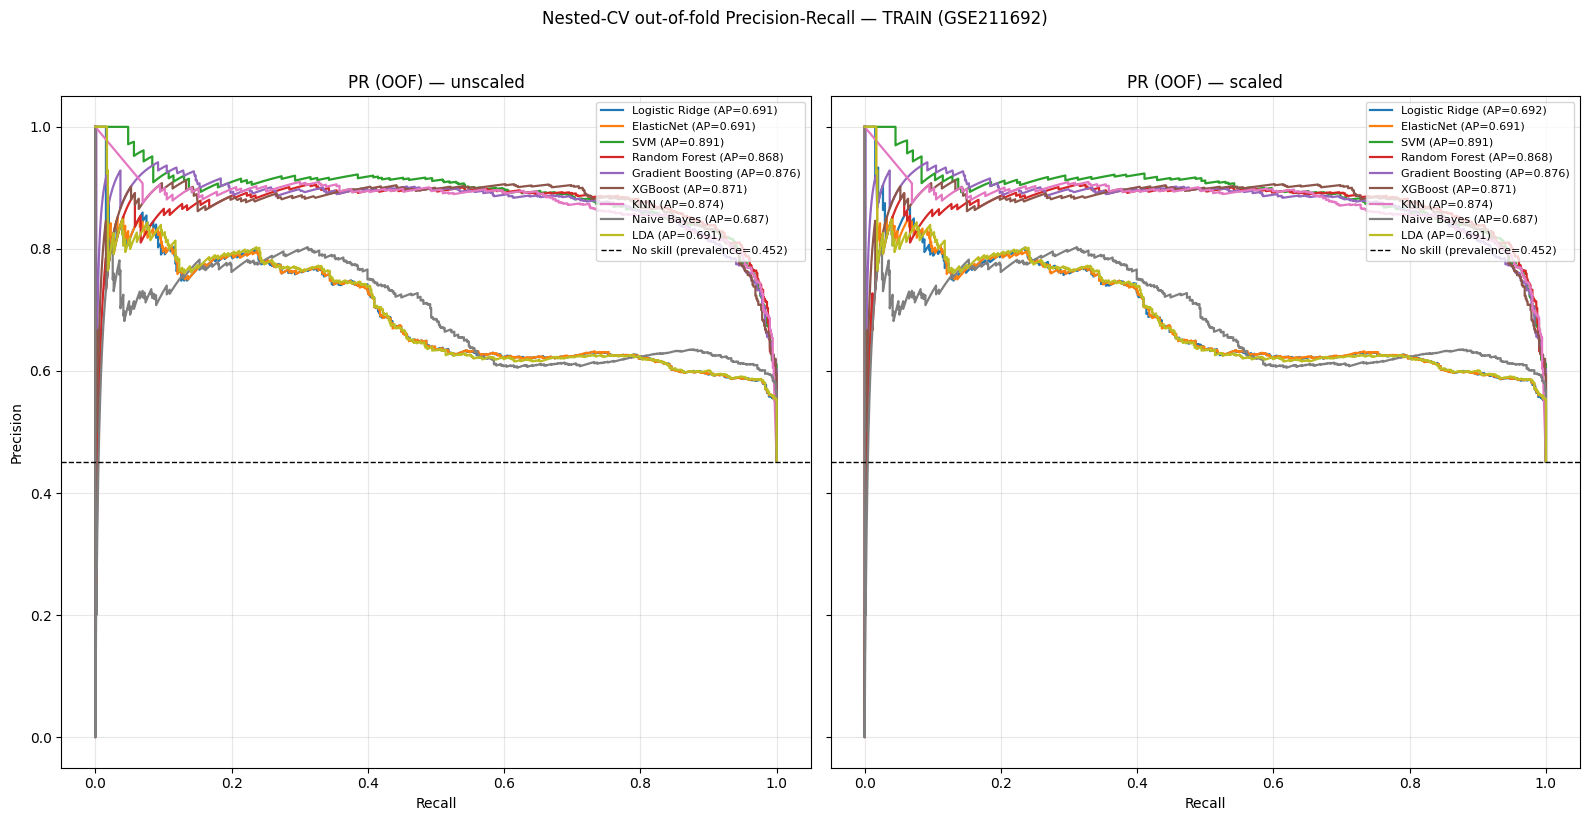

In [9]:
# OOF Precision-Recall curves for both scaling variants (nested CV on TRAIN).
baseline = (y_train == 1).mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    for name in MODELS:
        prec, rec, _ = precision_recall_curve(y_train, oof_proba[(name, variant)])
        ax.plot(rec, prec, lw=1.6,
                label=f"{name} (AP={oof_df.loc[(name, variant), 'AP']:.3f})")
    ax.axhline(baseline, color='k', ls='--', lw=1,
               label=f'No skill (prevalence={baseline:.3f})')
    ax.set_xlabel('Recall'); ax.set_title(f'PR (OOF) — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='upper right', fontsize=8)
axes[0].set_ylabel('Precision')
plt.suptitle('Nested-CV out-of-fold Precision-Recall — TRAIN (GSE211692)', y=1.02)
plt.tight_layout(); plt.show()

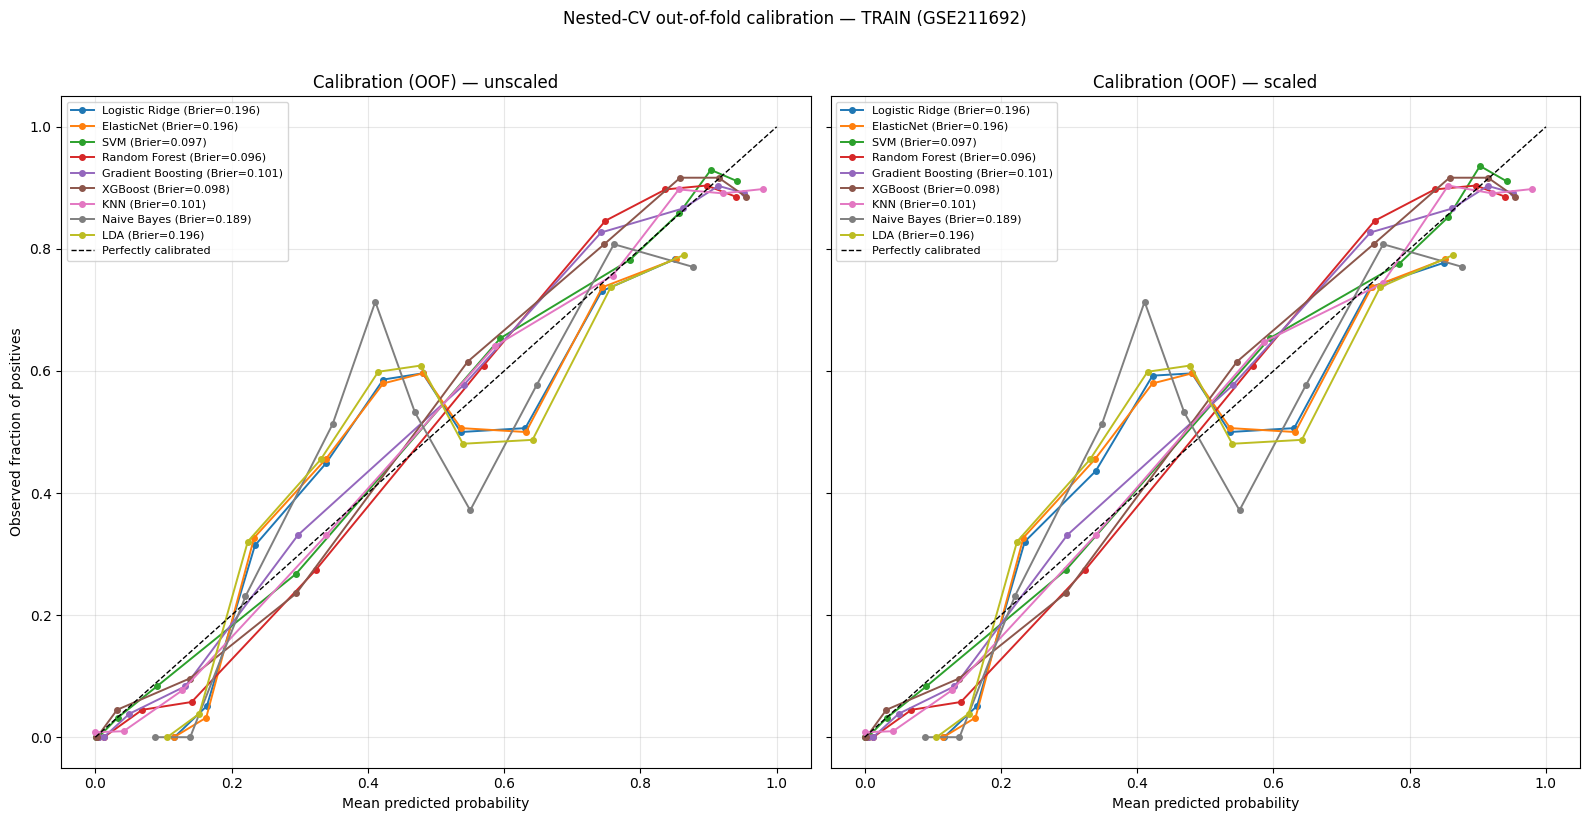

In [10]:
# OOF calibration curves (reliability diagrams) for both scaling variants (nested CV on TRAIN).
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    for name in MODELS:
        frac_pos, mean_pred = calibration_curve(y_train, oof_proba[(name, variant)],
                                                n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac_pos, marker='o', lw=1.4, markersize=4,
                label=f"{name} (Brier={oof_df.loc[(name, variant), 'Brier']:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfectly calibrated')
    ax.set_xlabel('Mean predicted probability'); ax.set_title(f'Calibration (OOF) — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('Observed fraction of positives')
plt.suptitle('Nested-CV out-of-fold calibration — TRAIN (GSE211692)', y=1.02)
plt.tight_layout(); plt.show()

4. External hold-out evaluation (GSE113486)

In [11]:
ext_rows = []
inner = StratifiedKFold(n_splits=INNER_K, shuffle=True, random_state=RANDOM_STATE)

for name, (estimator, grid) in MODELS.items():
    for scale in (True, False):
        gs = GridSearchCV(make_pipe(estimator, scale), grid,
                          scoring='roc_auc', cv=inner, n_jobs=-1, refit=True)
        gs.fit(X_train.values, y_train.values)
        best = gs.best_estimator_
        proba = best.predict_proba(X_test.values)[:, 1]
        pred  = best.predict(X_test.values)
        ext_rows.append({
            'Model': name,
            'Scaling': 'scaled' if scale else 'unscaled',
            'ROC-AUC':  roc_auc_score(y_test, proba),
            'Brier':    brier_score_loss(y_test, proba),
            'Accuracy': accuracy_score(y_test, pred),
            'best_params': gs.best_params_,
            'proba': proba,                 # kept for ROC / calibration curves
        })

ext_df = pd.DataFrame(ext_rows)
print('External test performance (GSE113486):')
display(ext_df[['Model', 'Scaling', 'ROC-AUC', 'Brier', 'Accuracy']]
        .round(3).set_index(['Model', 'Scaling']))

External test performance (GSE113486):


ROC-AUC  Brier  Accuracy
Model             Scaling                           
Logistic Ridge    scaled      0.854  0.158     0.757
                  unscaled    0.854  0.158     0.757
ElasticNet        scaled      0.854  0.158     0.757
                  unscaled    0.854  0.158     0.757
SVM               scaled      0.968  0.071     0.907
                  unscaled    0.968  0.071     0.907
Random Forest     scaled      0.982  0.059     0.929
                  unscaled    0.982  0.059     0.929
Gradient Boosting scaled      0.968  0.066     0.921
                  unscaled    0.968  0.066     0.921
XGBoost           scaled      0.974  0.062     0.936
                  unscaled    0.974  0.062     0.936
KNN               scaled      0.998  0.056     0.936
                  unscaled    0.998  0.056     0.936
Naive Bayes       scaled      0.877  0.149     0.771
                  unscaled    0.877  0.149     0.771
LDA               scaled      0.854  0.158     0.750
                  unscaled    0.854  0.158     0.750

5. ROC curve - unscaled vs scaled

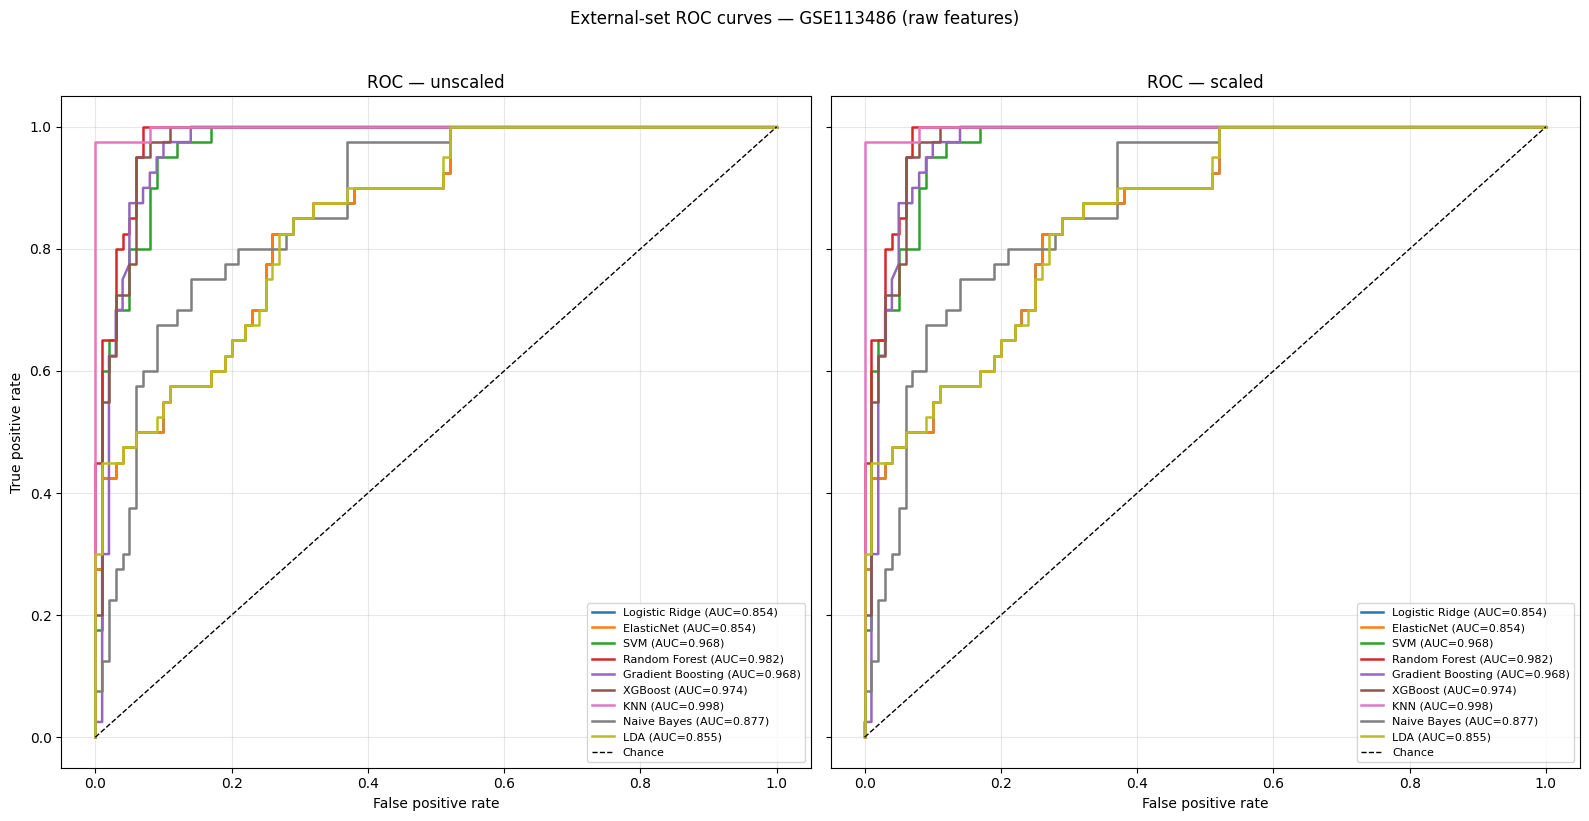

In [12]:
# ROC curves for both scaling variants (external test GSE113486).
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    sub = ext_df[ext_df['Scaling'] == variant].set_index('Model')
    for name in MODELS:
        proba = sub.loc[name, 'proba']
        fpr, tpr, _ = roc_curve(y_test, proba)
        ax.plot(fpr, tpr, lw=1.8,
                label=f"{name} (AUC={sub.loc[name, 'ROC-AUC']:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
    ax.set_xlabel('False positive rate'); ax.set_title(f'ROC — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('True positive rate')
plt.suptitle('External-set ROC curves — GSE113486 (raw features)', y=1.02)
plt.tight_layout(); plt.show()

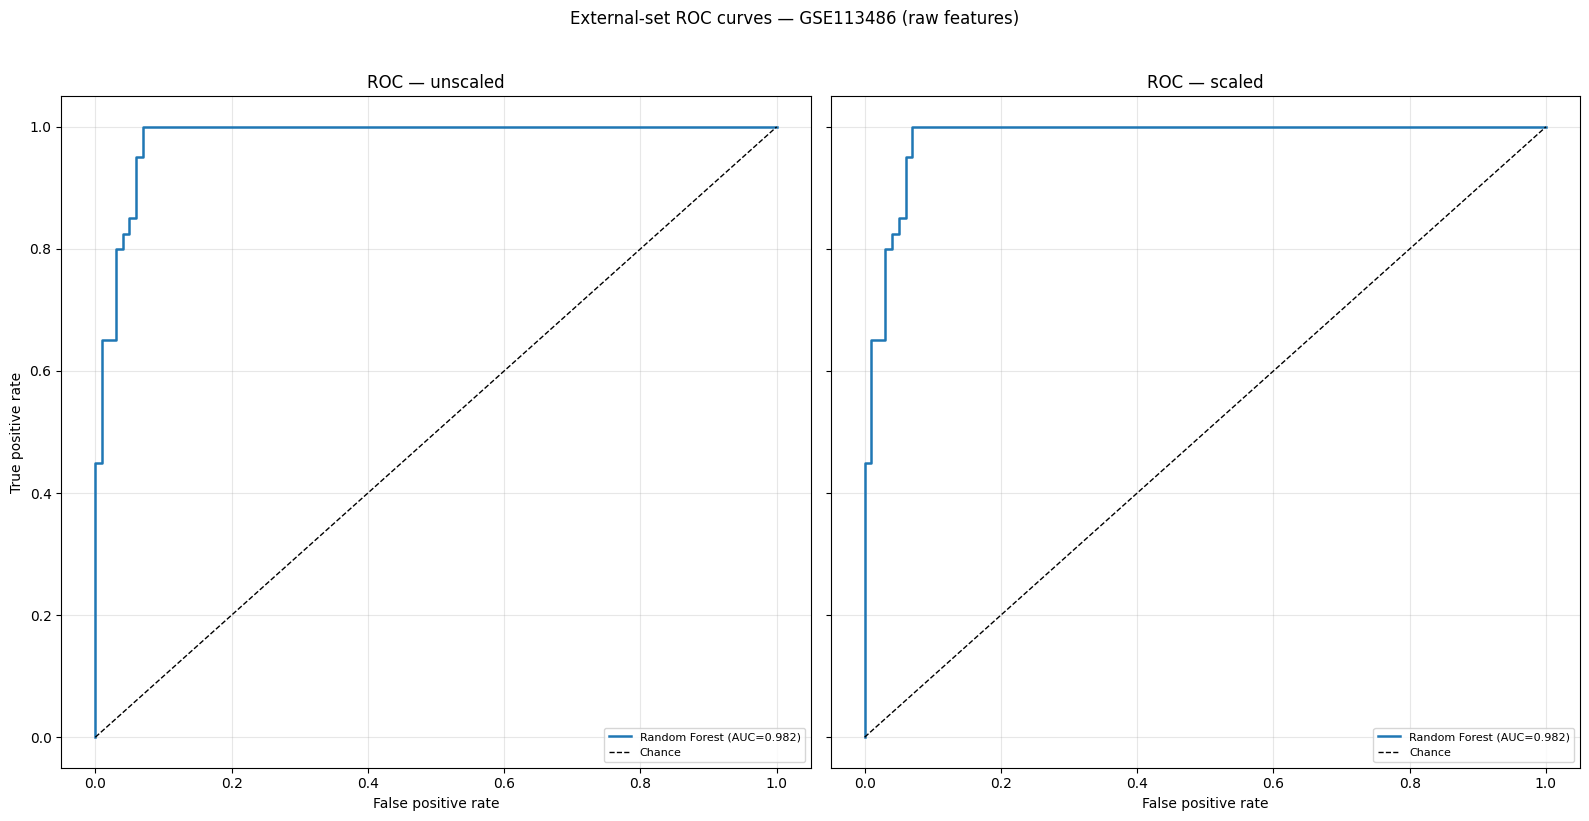

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Chỉ định tên mô hình bạn muốn vẽ (hãy chắc chắn rằng tên này khớp chính xác với tên trong DataFrame của bạn)
model_name = 'Random Forest'

# ROC curves for both scaling variants (external test GSE113486).
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, variant in zip(axes, ('unscaled', 'scaled')):
    # Lọc dữ liệu theo 'Scaling' và set index là 'Model'
    sub = ext_df[ext_df['Scaling'] == variant].set_index('Model')

    # Lấy xác suất dự đoán (proba) cho mô hình 'logistic ridge'
    proba = sub.loc[model_name, 'proba']

    # Tính toán False Positive Rate và True Positive Rate
    fpr, tpr, _ = roc_curve(y_test, proba)

    # Vẽ đường cong ROC cho mô hình
    ax.plot(fpr, tpr, lw=1.8,
            label=f"{model_name} (AUC={sub.loc[model_name, 'ROC-AUC']:.3f})")

    # Vẽ đường Chance (random guess)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')

    # Tuỳ chỉnh biểu đồ
    ax.set_xlabel('False positive rate')
    ax.set_title(f'ROC — {variant}')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right', fontsize=8)

axes[0].set_ylabel('True positive rate')
plt.suptitle('External-set ROC curves — GSE113486 (raw features)', y=1.02)
plt.tight_layout()
plt.show()

6. Precision - Recall curve - unscaled vs scaled

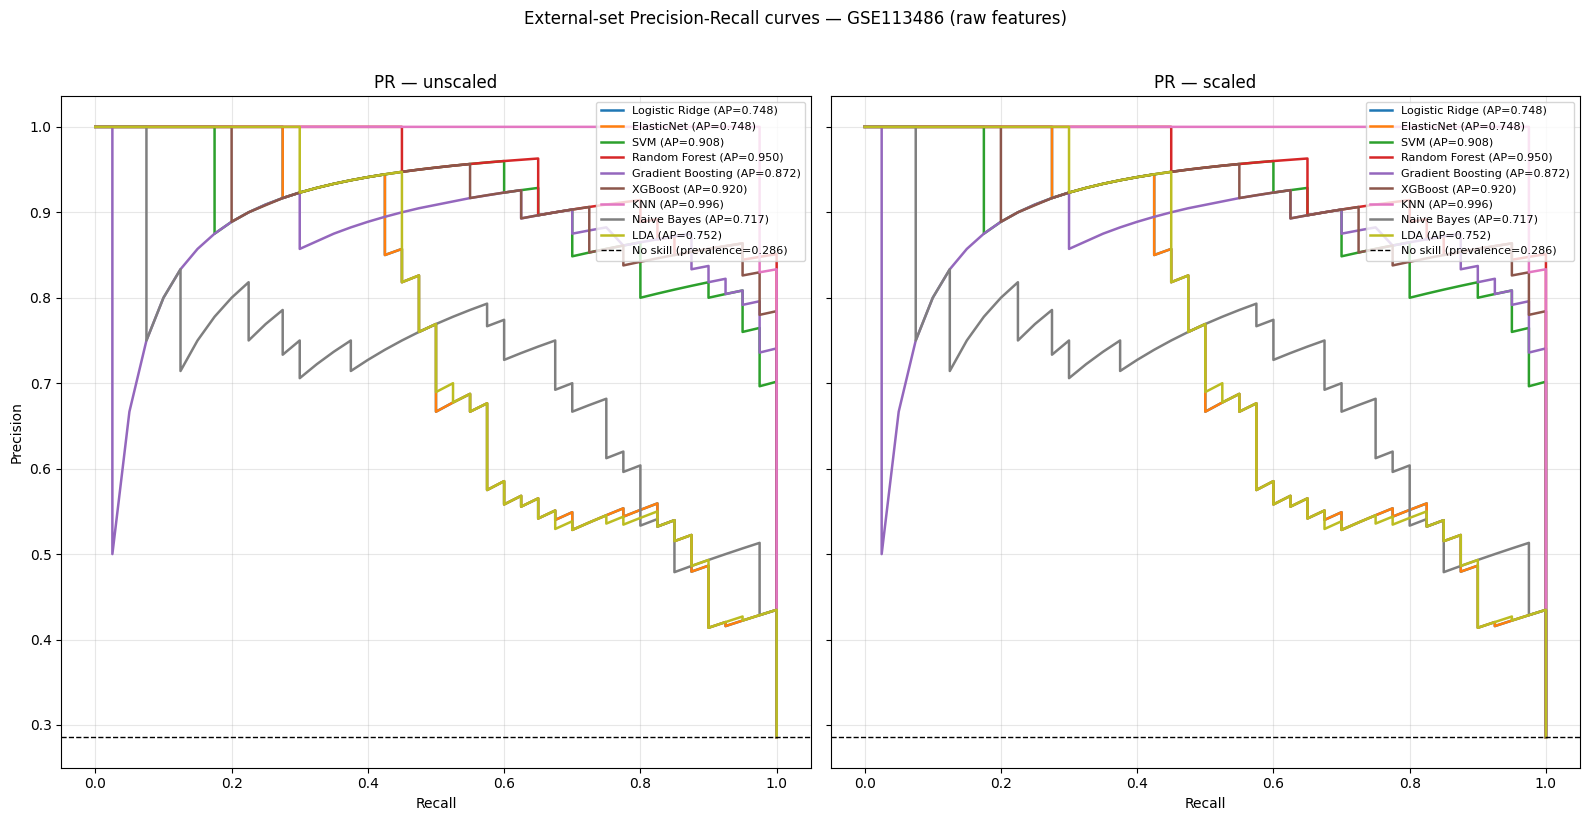

In [14]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Precision-Recall curves for both scaling variants (external test GSE113486).
# PR curves are more informative than ROC under class imbalance (here p = 40/140).
baseline = (y_test == 1).mean()          # no-skill precision = test prevalence

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    sub = ext_df[ext_df['Scaling'] == variant].set_index('Model')
    for name in MODELS:
        proba = sub.loc[name, 'proba']
        prec, rec, _ = precision_recall_curve(y_test, proba)
        ap = average_precision_score(y_test, proba)
        ax.plot(rec, prec, lw=1.8, label=f'{name} (AP={ap:.3f})')
    ax.axhline(baseline, color='k', ls='--', lw=1,
               label=f'No skill (prevalence={baseline:.3f})')
    ax.set_xlabel('Recall'); ax.set_title(f'PR — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='upper right', fontsize=8)
axes[0].set_ylabel('Precision')
plt.suptitle('External-set Precision-Recall curves — GSE113486 (raw features)', y=1.02)
plt.tight_layout(); plt.show()

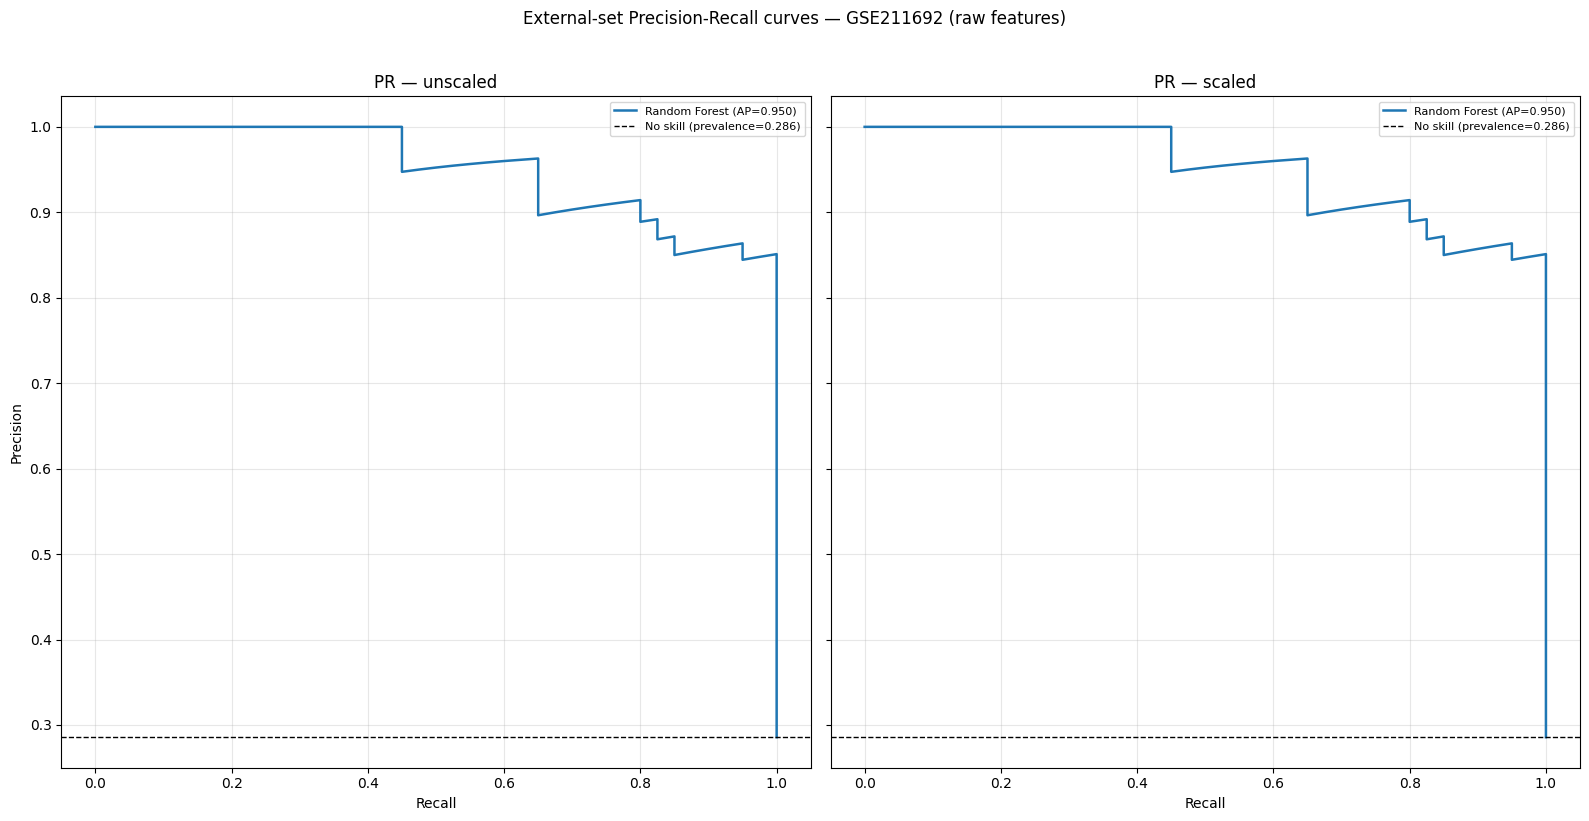

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Chỉ định tên mô hình bạn muốn vẽ
model_name = 'Random Forest'

# Precision-Recall curves for both scaling variants (external test GSE113486).
baseline = (y_test == 1).mean()          # no-skill precision = test prevalence

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, variant in zip(axes, ('unscaled', 'scaled')):
    # Lọc dữ liệu theo 'Scaling' và set index là 'Model'
    sub = ext_df[ext_df['Scaling'] == variant].set_index('Model')

    # Lấy xác suất dự đoán (proba) cho mô hình 'logistic ridge'
    proba = sub.loc[model_name, 'proba']

    # Tính toán Precision, Recall và Average Precision (AP)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)

    # Vẽ đường cong PR cho mô hình
    ax.plot(rec, prec, lw=1.8, label=f'{model_name} (AP={ap:.3f})')

    # Vẽ đường baseline (no skill)
    ax.axhline(baseline, color='k', ls='--', lw=1,
               label=f'No skill (prevalence={baseline:.3f})')

    # Tuỳ chỉnh biểu đồ
    ax.set_xlabel('Recall')
    ax.set_title(f'PR — {variant}')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=8)

axes[0].set_ylabel('Precision')
plt.suptitle('External-set Precision-Recall curves — GSE211692 (raw features)', y=1.02)
plt.tight_layout()
plt.show()

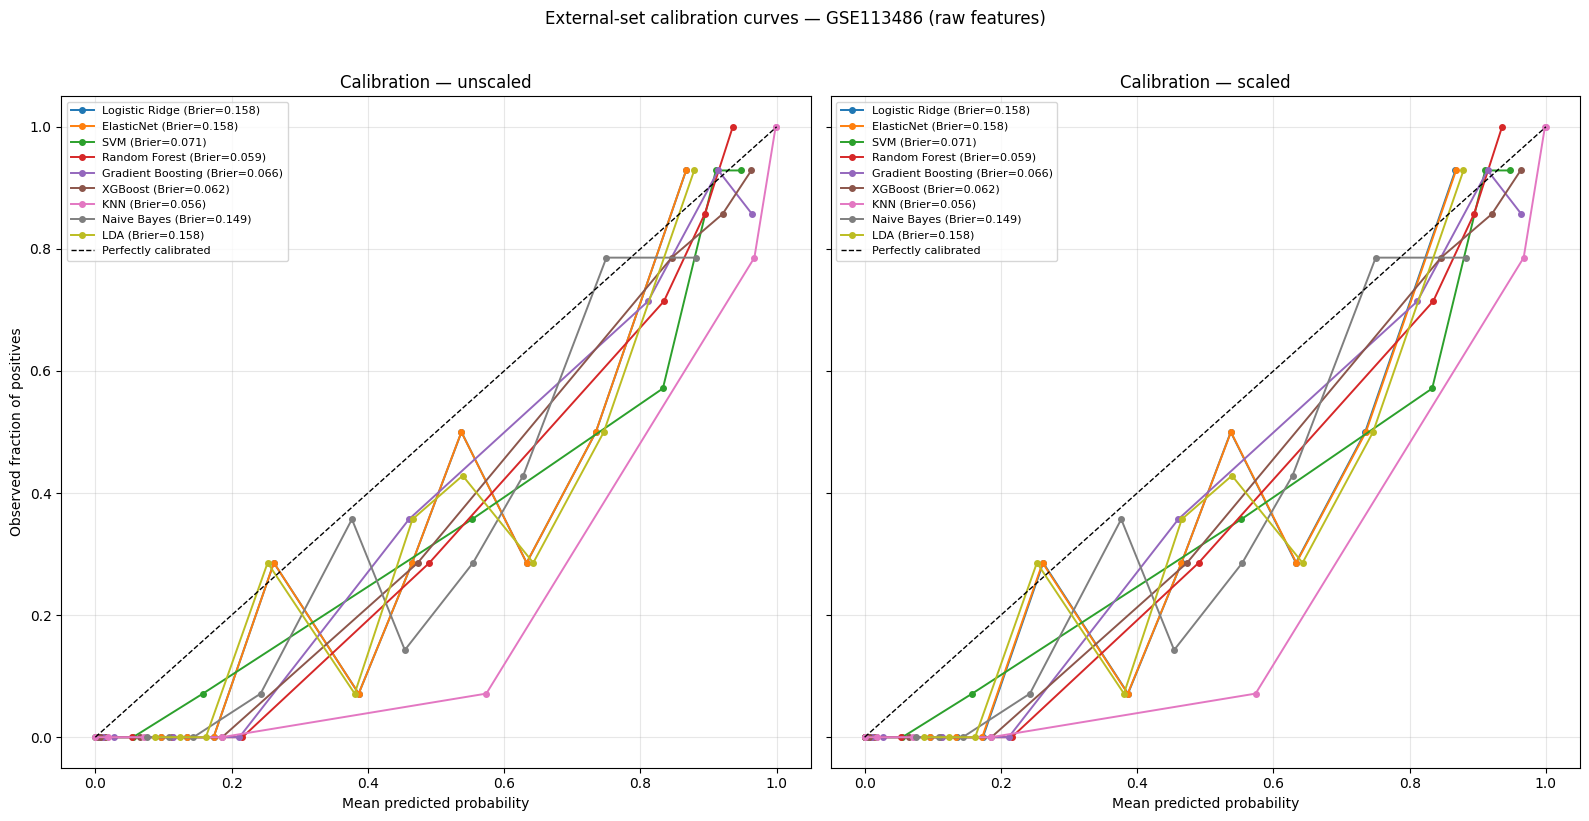

In [16]:
# Calibration curves (reliability diagrams) for both scaling variants (external test).
# Predicted probability vs observed positive frequency; the diagonal = perfect calibration.
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, variant in zip(axes, ('unscaled', 'scaled')):
    sub = ext_df[ext_df['Scaling'] == variant].set_index('Model')
    for name in MODELS:
        proba = sub.loc[name, 'proba']
        frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10,
                                                strategy='quantile')
        ax.plot(mean_pred, frac_pos, marker='o', lw=1.4, markersize=4,
                label=f"{name} (Brier={sub.loc[name, 'Brier']:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfectly calibrated')
    ax.set_xlabel('Mean predicted probability'); ax.set_title(f'Calibration — {variant}')
    ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('Observed fraction of positives')
plt.suptitle('External-set calibration curves — GSE113486 (raw features)', y=1.02)
plt.tight_layout(); plt.show()

In [17]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

def sens_spec(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn), tn / (tn + fp)

thr_rows = []
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for _, row in ext_df.iterrows():
    name, variant = row['Model'], row['Scaling']
    estimator, _ = MODELS[name]
    pipe = clone(make_pipe(estimator, scale=(variant == 'scaled'))).set_params(**row['best_params'])
    # leakage-free threshold: out-of-fold TRAIN probabilities, best params fixed
    oof = cross_val_predict(pipe, X_train.values, y_train.values, cv=cv5,
                            method='predict_proba', n_jobs=-1)[:, 1]
    fpr, tpr, thr = roc_curve(y_train.values, oof)
    j_thr = thr[np.argmax(tpr - fpr)]
    proba = row['proba']                       # stored external-test probabilities
    pred_05 = (proba >= 0.5).astype(int)
    pred_j  = (proba >= j_thr).astype(int)
    sens_05, spec_05 = sens_spec(y_test, pred_05)   # pre-tuning (default 0.5)
    sens_j,  spec_j  = sens_spec(y_test, pred_j)     # post-tuning (Youden J)
    # ROC-AUC & Brier are threshold-independent -> one value, valid pre and post
    thr_rows.append({
        'Model': name, 'Scaling': variant, 'Youden_thr': j_thr,
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Brier':   brier_score_loss(y_test, proba),
        'Sens@0.5': sens_05, 'Spec@0.5': spec_05, 'Acc@0.5': accuracy_score(y_test, pred_05),
        'Sens@thr': sens_j,  'Spec@thr': spec_j,  'Acc@thr': accuracy_score(y_test, pred_j),
    })

thr_df = pd.DataFrame(thr_rows).set_index(['Model', 'Scaling'])
print('Threshold from Youden J on TRAIN (5-fold OOF), applied to external test (GSE113486):')
display(thr_df.round(3))
print(f"\nMean Accuracy:    0.5={thr_df['Acc@0.5'].mean():.3f} -> tuned={thr_df['Acc@thr'].mean():.3f}")
print(f"Mean Sensitivity: 0.5={thr_df['Sens@0.5'].mean():.3f} -> tuned={thr_df['Sens@thr'].mean():.3f}")
print(f"Mean Specificity: 0.5={thr_df['Spec@0.5'].mean():.3f} -> tuned={thr_df['Spec@thr'].mean():.3f}")


Threshold from Youden J on TRAIN (5-fold OOF), applied to external test (GSE113486):


Youden_thr  ROC-AUC  Brier  Sens@0.5  Spec@0.5  \
Model             Scaling                                                    
Logistic Ridge    scaled         0.235    0.854  0.158     0.775      0.75   
                  unscaled       0.235    0.854  0.158     0.775      0.75   
ElasticNet        scaled         0.228    0.854  0.158     0.775      0.75   
                  unscaled       0.229    0.854  0.158     0.775      0.75   
SVM               scaled         0.405    0.968  0.071     0.975      0.88   
                  unscaled       0.405    0.968  0.071     0.975      0.88   
Random Forest     scaled         0.442    0.982  0.059     1.000      0.90   
                  unscaled       0.442    0.982  0.059     1.000      0.90   
Gradient Boosting scaled         0.479    0.968  0.066     0.975      0.90   
                  unscaled       0.479    0.968  0.066     0.975      0.90   
XGBoost           scaled         0.394    0.974  0.062     0.975      0.92   
                  unscaled       0.394    0.974  0.062     0.975      0.92   
KNN               scaled         0.412    0.998  0.056     1.000      0.91   
                  unscaled       0.413    0.998  0.056     1.000      0.91   
Naive Bayes       scaled         0.365    0.877  0.149     0.800      0.76   
                  unscaled       0.365    0.877  0.149     0.800      0.76   
LDA               scaled         0.224    0.854  0.158     0.750      0.75   
                  unscaled       0.224    0.854  0.158     0.750      0.75   

                            Acc@0.5  Sens@thr  Spec@thr  Acc@thr  
Model             Scaling                                         
Logistic Ridge    scaled      0.757     1.000      0.48    0.629  
                  unscaled    0.757     1.000      0.48    0.629  
ElasticNet        scaled      0.757     1.000      0.48    0.629  
                  unscaled    0.757     1.000      0.48    0.629  
SVM               scaled      0.907     0.975      0.88    0.907  
                  unscaled    0.907     0.975      0.88    0.907  
Random Forest     scaled      0.929     1.000      0.89    0.921  
                  unscaled    0.929     1.000      0.89    0.921  
Gradient Boosting scaled      0.921     0.975      0.89    0.914  
                  unscaled    0.921     0.975      0.89    0.914  
XGBoost           scaled      0.936     1.000      0.88    0.914  
                  unscaled    0.936     1.000      0.88    0.914  
KNN               scaled      0.936     1.000      0.88    0.914  
                  unscaled    0.936     1.000      0.88    0.914  
Naive Bayes       scaled      0.771     0.975      0.61    0.714  
                  unscaled    0.771     0.975      0.61    0.714  
LDA               scaled      0.750     1.000      0.48    0.629  
                  unscaled    0.750     1.000      0.48    0.629


Mean Accuracy:    0.5=0.852 -> tuned=0.797
Mean Sensitivity: 0.5=0.892 -> tuned=0.992
Mean Specificity: 0.5=0.836 -> tuned=0.719


TCGA ∩ GSE211692 ∩ GSE113486: ['hsa-miR-1307-5p', 'hsa-miR-200a-3p', 'hsa-miR-337-3p']


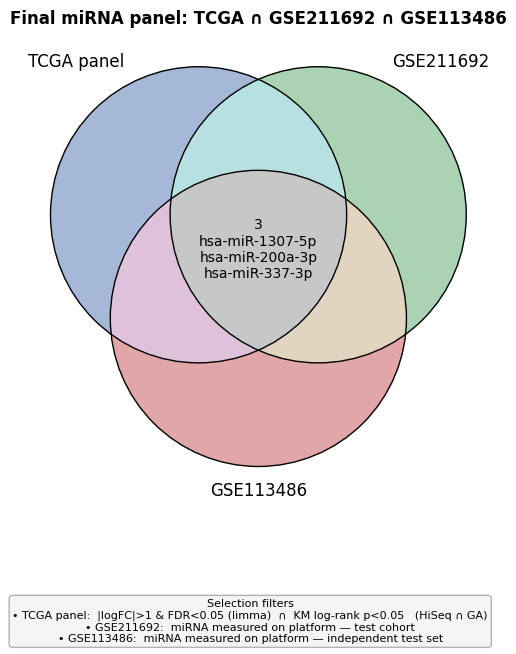

In [19]:
!pip install -q matplotlib-venn

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn3_circles

# --- Panel cuối cùng ---
final_panel = {"hsa-miR-200a-3p", "hsa-miR-337-3p", "hsa-miR-1307-5p"}

# 2 cohort GEO dùng kiểm định: GSE211692 (train) + GSE113486 (test set)
g211  = set(pd.read_csv("GSE211692_Raw_Full_Probe.csv",  nrows=1).columns)
g113 = set(pd.read_csv("GSE113486_Raw_Full_Probe.csv", nrows=1).columns)

# Giới hạn coverage GEO trong phạm vi panel -> chỉ xét panel có đo được hay không
A = final_panel
B = final_panel & g211
C = final_panel & g113
print("TCGA ∩ GSE211692 ∩ GSE113486:", sorted(A & B & C))

# 7 vùng của Venn 3 tập
regions = {"100": A-B-C, "010": B-A-C, "001": C-A-B,
           "110": (A&B)-C, "101": (A&C)-B, "011": (B&C)-A, "111": A&B&C}

plt.figure(figsize=(6.5, 6.8))
v = venn3(subsets=(1,) * 7, set_labels=("TCGA panel", "GSE211692", "GSE113486"),
          set_colors=("#4C72B0", "#55A868", "#C44E52"), alpha=0.5)
venn3_circles(subsets=(1,) * 7, linewidth=1)

# Ghi số + tên miRNA; vùng rỗng để trống
for rid, members in regions.items():
    lbl = v.get_label_by_id(rid)
    if lbl is None:
        continue
    lbl.set_text("" if not members else f"{len(members)}\n" + "\n".join(sorted(members)))
    lbl.set_fontsize(10)

# Điều kiện lọc của từng tập
filt = ("Selection filters\n"
        "• TCGA panel:  |logFC|>1 & FDR<0.05 (limma)  ∩  KM log-rank p<0.05   (HiSeq ∩ GA)\n"
        "• GSE211692:  miRNA measured on platform — test cohort\n"
        "• GSE113486:  miRNA measured on platform — independent test set")
plt.gcf().text(0.5, 0.03, filt, ha="center", va="bottom", fontsize=8,
               bbox=dict(boxstyle="round", fc="#f5f5f5", ec="0.7"))

plt.title("Final miRNA panel: TCGA ∩ GSE211692 ∩ GSE113486", fontweight="bold")
plt.subplots_adjust(bottom=0.24, top=0.93)
plt.show()
